# Extractive Summarization Pipeline
BanglaBERT + LIME + ROUGE/BLEU/BERTScore

In [1]:
!pip install -q transformers huggingface_hub
!pip install -q lime
!pip install -q rouge-score
!pip install -q bert-score
!pip install -q nltk
!pip install -q sentencepiece

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 84.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26

True

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import json
import re
import time
import warnings
from pathlib import Path
from typing import List, Optional
from tqdm.auto import tqdm
tqdm.pandas()
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn import svm

from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='darkgrid')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('CUDA:', torch.cuda.is_available())

Device: cuda
CUDA: True


## Configuration

In [3]:
CONFIG = {
    'data_path'         : '/kaggle/input/datasets/swagotodas/newsclassification2/ittefaq.jsonl',
    'text_column'       : 'Content',
    'label_column'      : 'Category',
    'model_name'        : 'csebuetnlp/banglabert',
    'max_seq_len'       : 200,
    'tokenize_batch'    : 64,
    'embed_batch'       : 128,
    'subset_start'      : 80000, # Starting index
    'subset_size'       : 10000, # Number of records to take
    'top_n_sentences'   : 3,     #ignore if num sentence is less than 3
    'min_sentence_len'  : 10,
    'lime_num_features' : 5,
    'lime_num_samples'  : 10,
    'eval_sample'       : 1000,
    'bertscore_sample'  : 200,
    'bertscore_lang'    : 'bn',
    'output_dir'        : '/kaggle/working/outputs',
    'seed'              : 42,
}

np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
Path(CONFIG['output_dir']).mkdir(exist_ok=True)

## 1. Data Loading

In [4]:
df = pd.read_json(CONFIG['data_path'], lines=True)
print('Full dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
df.head()

Full dataset shape: (677819, 5)
Columns: ['Title', 'Category', 'Time', 'Content', 'Tags']


,Title,Category,Time,Content,Tags
0,খুলনায় সাংবাদিক হেদায়েত তিনদিনের রিমান্ডে,সারাদেশ,"প্রকাশ : ০২ জানুয়ারি ২০১৯, ১৩:৪৭",ডিজিটাল নিরাপত্তা আইনে গ্রেফতার বাংলা ট্রিবিউন...,
1,রাতের তাপমাত্রা আরো কমতে পারে,জাতীয়,"প্রকাশ : ০২ জানুয়ারি ২০১৯, ১৩:৫০",আগামী শুক্রবার পর্যন্ত রাতের তাপমাত্রা আরো কমত...,
2,"সিরিজ নিশ্চিত চায় দক্ষিণ আফ্রিকা, পাকিস্তানের ...",খেলা,"প্রকাশ : ০২ জানুয়ারি ২০১৯, ১৩:৫৪",সেঞ্চুরিয়ানে সিরিজের প্রথম টেস্টে পাকিস্তানকে ...,
3,নীলফামারী-৪ আসনে ৩ প্রার্থীর জামানত বাজেয়াপ্ত,সারাদেশ,"প্রকাশ : ০২ জানুয়ারি ২০১৯, ১৩:৫৫",একাদশ জাতীয় সংসদ নির্বাচনে নীলফামারী-৪ (সৈয়দপ...,
4,৪৮ ঘণ্টার মধ্যে নির্বাচনী ব্যানার পোস্টার অপসা...,রাজধানী,"প্রকাশ : ০২ জানুয়ারি ২০১৯, ১৪:০৩",আগামী ৪৮ ঘণ্টার মধ্যে ঢাকা দক্ষিণ সিটি কর্পোরে...,


In [5]:
start = CONFIG['subset_start']
end = start + CONFIG['subset_size']

# Select the specific range using CONFIG variables
subdf = df.iloc[start:end].copy()

subdf = subdf.dropna(subset=[CONFIG['text_column']]).reset_index(drop=True)
print(f'Working subset (Records {start+1} to {end}):', subdf.shape)

Working subset (Records 80001 to 90000): (10000, 5)


## 2. Preprocessing

**If any content has less than 3 sentences, ignore them**

In [6]:
from nltk.tokenize import sent_tokenize


def clean_text(text: str) -> str:
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[\x00-\x1f\x7f-\x9f]', '', text)
    return text.strip()


def sentence_split(text: str, min_len: int = 10) -> List[str]:
    # Bangla sentence boundary: ।  plus standard punctuation
    raw = re.split(r'(?<=[।?!.])\s+', clean_text(text))
    if len(raw) < 2:
        raw = sent_tokenize(text)
    return [s.strip() for s in raw if len(s.strip()) >= min_len]


subdf['sentences'] = subdf[CONFIG['text_column']].progress_apply(
    lambda t: sentence_split(t, CONFIG['min_sentence_len'])
)
subdf['num_sentences'] = subdf['sentences'].apply(len)
subdf['clean_text']    = subdf[CONFIG['text_column']].apply(clean_text)

# keep only docs with enough sentences to summarize

subdf = subdf[subdf['num_sentences'] >= CONFIG['top_n_sentences']].reset_index(drop=True)
print('After filter:', len(subdf))
print('Avg sentences/doc:', subdf['num_sentences'].mean().round(1))

  0%|          | 0/10000 [00:00<?, ?it/s]

After filter: 9498
Avg sentences/doc: 15.9


## 3. Feature Extraction — BERT + BoW + TF-IDF

In [7]:
model_name = CONFIG['model_name']
tokenizer  = AutoTokenizer.from_pretrained(model_name)
bert       = AutoModel.from_pretrained(model_name)

if torch.cuda.device_count() > 1:
    bert = nn.DataParallel(bert)
bert = bert.to(device)
bert.eval()
print('Model loaded on', device)

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
electra.embeddings.position_ids                   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Model loaded on cuda


In [8]:
texts = subdf[CONFIG['text_column']].tolist()
batch_size = CONFIG['tokenize_batch']

input_ids_list       = []
attention_masks_list = []

for i in tqdm(range(0, len(texts), batch_size), desc='Tokenizing'):
    batch_texts = texts[i:i+batch_size]
    encoded = tokenizer(
        batch_texts,
        add_special_tokens=True,
        padding=True,
        truncation=True,
        max_length=CONFIG['max_seq_len'],
        return_attention_mask=True,
        return_tensors='pt',
    )
    input_ids_list.append(encoded['input_ids'])
    attention_masks_list.append(encoded['attention_mask'])

input_ids       = torch.cat(input_ids_list, dim=0)
attention_masks = torch.cat(attention_masks_list, dim=0)
print('input_ids shape:', input_ids.shape)

Tokenizing:   0%|          | 0/149 [00:00<?, ?it/s]

input_ids shape: torch.Size([9498, 200])


In [9]:
all_last_hidden_states = []
batch_proc = CONFIG['embed_batch']

with torch.no_grad():
    for i in tqdm(range(0, input_ids.size(0), batch_proc), desc='BERT embeddings'):
        b_ids   = input_ids[i:i+batch_proc].to(device)
        b_masks = attention_masks[i:i+batch_proc].to(device)
        out     = bert(b_ids, b_masks)
        # CLS token representation
        all_last_hidden_states.append(out[0][:, 0, :].detach().cpu())

X = torch.cat(all_last_hidden_states, dim=0).numpy()
print('BERT feature matrix:', X.shape)

BERT embeddings:   0%|          | 0/75 [00:00<?, ?it/s]

BERT feature matrix: (9498, 768)


In [10]:
text_arr = subdf[CONFIG['text_column']].values
y        = subdf[CONFIG['label_column']].values

bow_vec = CountVectorizer(max_features=768)
Y       = bow_vec.fit_transform(text_arr).toarray()

tfidf_vec = TfidfVectorizer(max_features=768)
Z         = tfidf_vec.fit_transform(text_arr).toarray()

combined_features = X + Y + Z
print('Combined feature matrix:', combined_features.shape)

Combined feature matrix: (9498, 768)


## 4. LIME-Guided Extractive Summarization

In [11]:
from lime.lime_text import LimeTextExplainer


class SentenceDataset(Dataset):
    def __init__(self, sentences, tok, max_len):
        self.enc = tok(
            sentences,
            padding=True,
            truncation=True,
            max_length=max_len,
            return_tensors='pt',
        )

    def __len__(self):
        return self.enc['input_ids'].shape[0]

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.enc.items()}


def mean_pool(token_emb, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(token_emb.size()).float()
    return torch.sum(token_emb * mask, 1) / torch.clamp(mask.sum(1), min=1e-9)


@torch.no_grad()
def encode_sentences(sentences: List[str], batch_size: int = 64) -> np.ndarray:
    if not sentences:
        return np.zeros((0, 768))
    ds     = SentenceDataset(sentences, tokenizer, CONFIG['max_seq_len'])
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    embs   = []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        out   = bert(**batch)
        embs.append(mean_pool(out.last_hidden_state, batch['attention_mask']).cpu().float().numpy())
    return np.vstack(embs)


def tfidf_scores(sentences: List[str], full_text: str) -> np.ndarray:
    try:
        vec    = TfidfVectorizer()
        mat    = vec.fit_transform(sentences + [full_text])
        scores = cosine_similarity(mat[:len(sentences)], mat[len(sentences):]).flatten()
    except Exception:
        scores = np.ones(len(sentences))
    return scores


def bert_scores(sentences: List[str]) -> np.ndarray:
    embs    = encode_sentences(sentences)
    doc_emb = embs.mean(axis=0, keepdims=True)
    return cosine_similarity(embs, doc_emb).flatten()


def position_scores(n: int) -> np.ndarray:
    s = np.zeros(n)
    if n > 0: s[0]  = 1.0
    if n > 1: s[-1] = 0.5
    if n > 2: s[1]  = 0.3
    return s


def normalize(arr: np.ndarray) -> np.ndarray:
    r = arr.max() - arr.min()
    return (arr - arr.min()) / (r + 1e-9)


def build_lime_predictor(sentences: List[str]):
    full_emb = encode_sentences([' '.join(sentences)])

    def predictor(texts: List[str]) -> np.ndarray:
        embs  = encode_sentences(texts)
        sims  = cosine_similarity(embs, full_emb).flatten()
        sims  = (sims + 1) / 2
        return np.column_stack([1 - sims, sims])

    return predictor


def lime_scores(sentences: List[str]) -> np.ndarray:
    explainer = LimeTextExplainer(class_names=['irrelevant', 'relevant'])
    predictor = build_lime_predictor(sentences)
    scores    = np.zeros(len(sentences))
    for i, sent in enumerate(sentences):
        if len(sent.split()) < 3:
            continue
        try:
            exp       = explainer.explain_instance(
                sent, predictor,
                num_features=CONFIG['lime_num_features'],
                num_samples=CONFIG['lime_num_samples'],
                labels=(1,),
            )
            scores[i] = sum(abs(w) for _, w in exp.as_list(label=1))
        except Exception:
            scores[i] = 0.0
    return scores


WEIGHTS = {'tfidf': 0.25, 'bert': 0.40, 'position': 0.10, 'lime': 0.25}


def summarize(text: str, top_n: int = 3) -> str:
    sentences = sentence_split(text, CONFIG['min_sentence_len'])
    if not sentences:
        return ''
    top_n = min(top_n, len(sentences))

    full_text = ' '.join(sentences)
    t  = normalize(tfidf_scores(sentences, full_text))
    b  = normalize(bert_scores(sentences))
    p  = normalize(position_scores(len(sentences)))
    lm = normalize(lime_scores(sentences))

    final   = (WEIGHTS['tfidf'] * t +
               WEIGHTS['bert']  * b +
               WEIGHTS['position'] * p +
               WEIGHTS['lime']  * lm)

    top_idx = sorted(np.argsort(final)[::-1][:top_n])
    return ' '.join(sentences[i] for i in top_idx)


print('Summarizer functions defined.')

Summarizer functions defined.


## 5. Run Summarization — Chunked

In [12]:
OUTPUT_PATH = Path(CONFIG['output_dir']) / 'summaries.jsonl'
CHUNK_SIZE  = 5000
N_TOTAL     = len(subdf)

t0 = time.time()
with open(OUTPUT_PATH, 'w', encoding='utf-8') as fout:
    for start in range(0, N_TOTAL, CHUNK_SIZE):
        chunk = subdf.iloc[start : start + CHUNK_SIZE]
        for text in tqdm(chunk[CONFIG['text_column']], desc=f'Chunk {start//CHUNK_SIZE+1}', leave=False):
            gen = summarize(text, top_n=CONFIG['top_n_sentences'])
            fout.write(json.dumps({'generated': gen, 'source': text[:200]}, ensure_ascii=False) + '\n')
        elapsed = (time.time() - t0) / 60
        done    = min(start + CHUNK_SIZE, N_TOTAL)
        print(f'[{done:>7,} / {N_TOTAL:,}]  {elapsed:.1f} min')

print('Done in', round((time.time()-t0)/60, 1), 'min')
print('Saved to', OUTPUT_PATH)

Chunk 1:   0%|          | 0/5000 [00:00<?, ?it/s]

[  5,000 / 9,498]  313.5 min


Chunk 2:   0%|          | 0/4498 [00:00<?, ?it/s]

[  9,498 / 9,498]  594.5 min
Done in 594.5 min
Saved to /kaggle/working/outputs/summaries.jsonl


## 6. Evaluation — ROUGE + BLEU + BERTScore

In [13]:
from rouge_score import rouge_scorer as rs_module
from bert_score import score as bert_score_fn
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction
from nltk.tokenize import word_tokenize


# Load generated summaries and pair with original texts as pseudo-references
# Since this is an unsupervised extractive task, we use the original article
# (truncated to ~3 sentences) as the reference, which is standard practice
# when no human-written summaries are available.

generated_texts = []
reference_texts = []

with open(OUTPUT_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        rec = json.loads(line)
        generated_texts.append(rec['generated'])

# Use first N docs from subdf; reference = first 3 sentences of original
for text in subdf[CONFIG['text_column']].values[:len(generated_texts)]:
    sents = sentence_split(text)
    reference_texts.append(' '.join(sents[:3]) if sents else text[:300])

EVAL_N  = min(CONFIG['eval_sample'],    len(generated_texts))
BS_N    = min(CONFIG['bertscore_sample'], len(generated_texts))

gen_eval   = generated_texts[:EVAL_N]
ref_eval   = reference_texts[:EVAL_N]
gen_bs     = generated_texts[:BS_N]
ref_bs     = reference_texts[:BS_N]

print('ROUGE/BLEU sample:', EVAL_N)
print('BERTScore sample:', BS_N)

ROUGE/BLEU sample: 1000
BERTScore sample: 200


In [14]:
scorer = rs_module.RougeScorer(['rouge1', 'rouge2', 'rougeL', 'rougeLsum'], use_stemmer=False)

rouge_records = []
for gen, ref in tqdm(zip(gen_eval, ref_eval), total=EVAL_N, desc='ROUGE'):
    s = scorer.score(ref, gen)
    rouge_records.append({
        'rouge1_p': s['rouge1'].precision,  'rouge1_r': s['rouge1'].recall,  'rouge1_f': s['rouge1'].fmeasure,
        'rouge2_p': s['rouge2'].precision,  'rouge2_r': s['rouge2'].recall,  'rouge2_f': s['rouge2'].fmeasure,
        'rougeL_p': s['rougeL'].precision,  'rougeL_r': s['rougeL'].recall,  'rougeL_f': s['rougeL'].fmeasure,
        'rougeLsum_f': s['rougeLsum'].fmeasure,
    })

rouge_df    = pd.DataFrame(rouge_records)
rouge_means = rouge_df.mean()

print('ROUGE-1  F1:', round(rouge_means['rouge1_f'], 4))
print('ROUGE-2  F1:', round(rouge_means['rouge2_f'], 4))
print('ROUGE-L  F1:', round(rouge_means['rougeL_f'], 4))
print('ROUGE-Lsum F1:', round(rouge_means['rougeLsum_f'], 4))

ROUGE:   0%|          | 0/1000 [00:00<?, ?it/s]

ROUGE-1  F1: 0.0055
ROUGE-2  F1: 0.0004
ROUGE-L  F1: 0.0055
ROUGE-Lsum F1: 0.0055


In [15]:
smoother      = SmoothingFunction().method4
bleu1_scores  = []
bleu4_scores  = []

for gen, ref in tqdm(zip(gen_eval, ref_eval), total=EVAL_N, desc='BLEU'):
    hyp  = list(gen.strip())
    refs = [list(ref.strip())]
    bleu1_scores.append(sentence_bleu(refs, hyp, weights=(1,0,0,0),        smoothing_function=smoother))
    bleu4_scores.append(sentence_bleu(refs, hyp, weights=(.25,.25,.25,.25), smoothing_function=smoother))

all_refs    = [[list(r.strip())] for r in ref_eval]
all_hyps    = [list(g.strip())   for g in gen_eval]
corpus_b1   = corpus_bleu(all_refs, all_hyps, weights=(1,0,0,0))
corpus_b4   = corpus_bleu(all_refs, all_hyps, weights=(.25,.25,.25,.25))

print('Sentence BLEU-1 (mean):', round(np.mean(bleu1_scores), 4))
print('Sentence BLEU-4 (mean):', round(np.mean(bleu4_scores), 4))
print('Corpus   BLEU-1:', round(corpus_b1, 4))
print('Corpus   BLEU-4:', round(corpus_b4, 4))

BLEU:   0%|          | 0/1000 [00:00<?, ?it/s]

Sentence BLEU-1 (mean): 0.647
Sentence BLEU-4 (mean): 0.516
Corpus   BLEU-1: 0.6352
Corpus   BLEU-4: 0.5195


In [16]:
P_b, R_b, F_b = bert_score_fn(
    gen_bs, ref_bs,
    lang=CONFIG['bertscore_lang'],
    device=str(device),
    verbose=True,
)

print('BERTScore Precision:', round(float(P_b.mean()), 4))
print('BERTScore Recall:',    round(float(R_b.mean()), 4))
print('BERTScore F1:',        round(float(F_b.mean()), 4))

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

...

calculating scores...
computing bert embedding.


  0%|          | 0/7 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/4 [00:00<?, ?it/s]

done in 4.70 seconds, 42.60 sentences/sec
BERTScore Precision: 0.7726
BERTScore Recall: 0.8164
BERTScore F1: 0.7934


## 7. Results Summary

In [17]:
results = {
    'rouge1_f1'      : round(rouge_means['rouge1_f'], 4),
    'rouge2_f1'      : round(rouge_means['rouge2_f'], 4),
    'rougeL_f1'      : round(rouge_means['rougeL_f'], 4),
    'rougeLsum_f1'   : round(rouge_means['rougeLsum_f'], 4),
    'bleu1_sentence' : round(float(np.mean(bleu1_scores)), 4),
    'bleu4_sentence' : round(float(np.mean(bleu4_scores)), 4),
    'bleu1_corpus'   : round(corpus_b1, 4),
    'bleu4_corpus'   : round(corpus_b4, 4),
    'bertscore_p'    : round(float(P_b.mean()), 4),
    'bertscore_r'    : round(float(R_b.mean()), 4),
    'bertscore_f1'   : round(float(F_b.mean()), 4),
}

results_df = pd.DataFrame(list(results.items()), columns=['Metric', 'Score'])
print(results_df.to_string(index=False))

with open(Path(CONFIG['output_dir']) / 'final_results.json', 'w') as f:
    json.dump(results, f, indent=2)

rouge_df['bleu1'] = bleu1_scores
rouge_df['bleu4'] = bleu4_scores
rouge_df['generated'] = gen_eval
rouge_df['reference'] = ref_eval
rouge_df.to_csv(Path(CONFIG['output_dir']) / 'per_sample_metrics.csv', index=False)

        Metric  Score
     rouge1_f1 0.0055
     rouge2_f1 0.0004
     rougeL_f1 0.0055
  rougeLsum_f1 0.0055
bleu1_sentence 0.6470
bleu4_sentence 0.5160
  bleu1_corpus 0.6352
  bleu4_corpus 0.5195
   bertscore_p 0.7726
   bertscore_r 0.8164
  bertscore_f1 0.7934


## 8. Visualizations

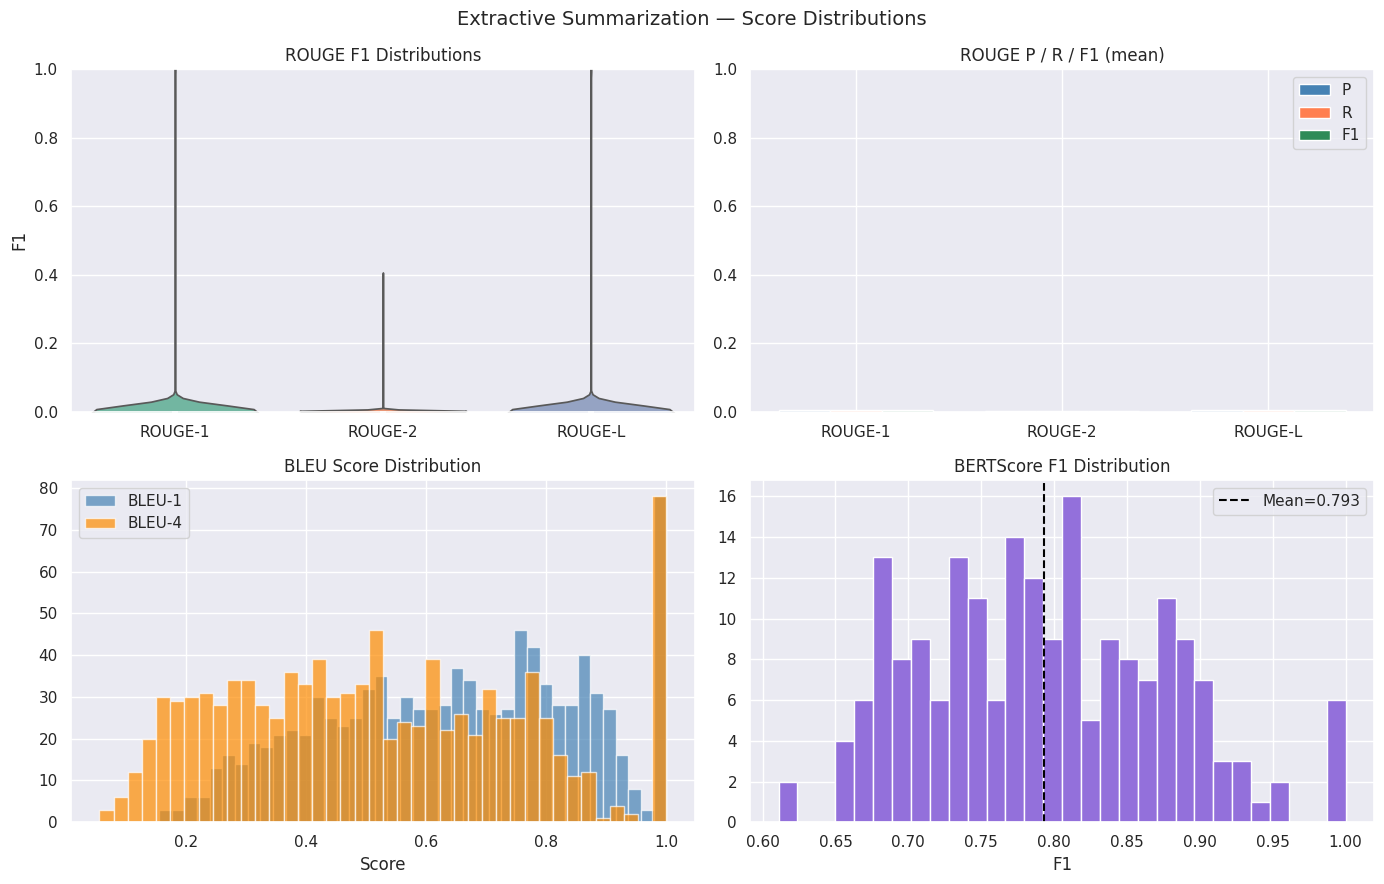

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Extractive Summarization — Score Distributions', fontsize=14)

# ROUGE F1 violin
ax = axes[0, 0]
melt = rouge_df[['rouge1_f','rouge2_f','rougeL_f']].melt(var_name='m', value_name='F1')
melt['m'] = melt['m'].map({'rouge1_f':'ROUGE-1','rouge2_f':'ROUGE-2','rougeL_f':'ROUGE-L'})
sns.violinplot(data=melt, x='m', y='F1', palette='Set2', ax=ax)
ax.set_title('ROUGE F1 Distributions')
ax.set_xlabel('')
ax.set_ylim(0, 1)

# ROUGE P/R/F1 grouped bar
ax = axes[0, 1]
labels = ['ROUGE-1','ROUGE-2','ROUGE-L']
p_vals = [rouge_means['rouge1_p'], rouge_means['rouge2_p'], rouge_means['rougeL_p']]
r_vals = [rouge_means['rouge1_r'], rouge_means['rouge2_r'], rouge_means['rougeL_r']]
f_vals = [rouge_means['rouge1_f'], rouge_means['rouge2_f'], rouge_means['rougeL_f']]
x = np.arange(3)
w = 0.25
ax.bar(x-w, p_vals, w, label='P',  color='steelblue')
ax.bar(x,   r_vals, w, label='R',  color='coral')
ax.bar(x+w, f_vals, w, label='F1', color='seagreen')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title('ROUGE P / R / F1 (mean)')
ax.set_ylim(0, 1)
ax.legend()

# BLEU histogram
ax = axes[1, 0]
ax.hist(bleu1_scores, bins=40, alpha=0.7, color='steelblue',  label='BLEU-1')
ax.hist(bleu4_scores, bins=40, alpha=0.7, color='darkorange', label='BLEU-4')
ax.set_title('BLEU Score Distribution')
ax.set_xlabel('Score')
ax.legend()

# BERTScore histogram
ax = axes[1, 1]
ax.hist(F_b.numpy(), bins=30, color='mediumpurple', edgecolor='white')
ax.axvline(float(F_b.mean()), color='black', linestyle='--', label=f'Mean={float(F_b.mean()):.3f}')
ax.set_title('BERTScore F1 Distribution')
ax.set_xlabel('F1')
ax.legend()

plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

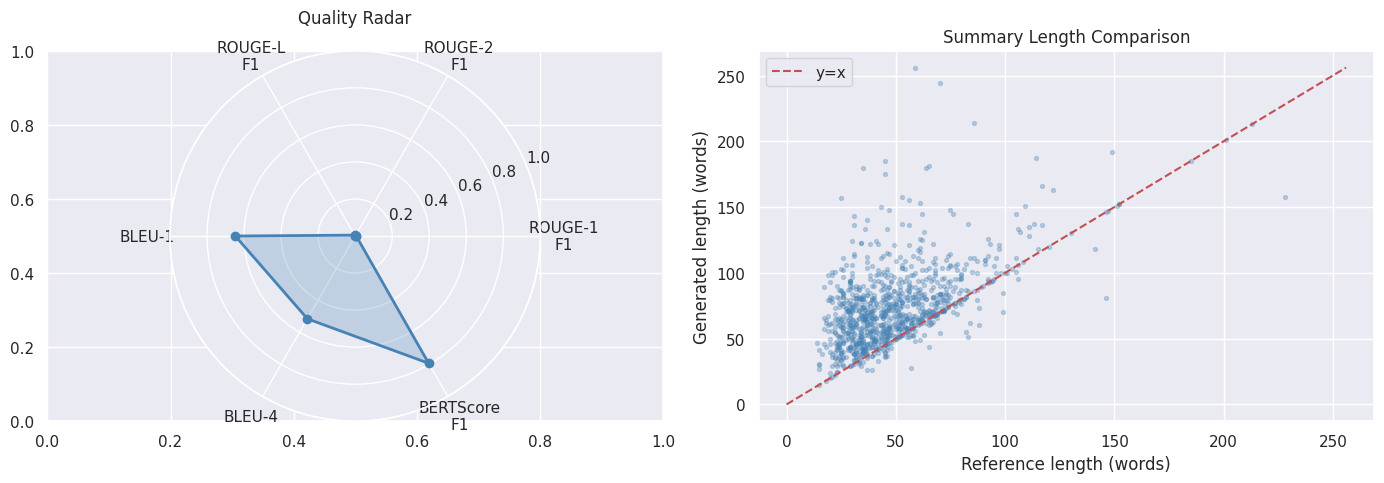

In [19]:
# Summary length comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Radar chart
categories = ['ROUGE-1\nF1','ROUGE-2\nF1','ROUGE-L\nF1','BLEU-1','BLEU-4','BERTScore\nF1']
values     = [results['rouge1_f1'], results['rouge2_f1'], results['rougeL_f1'],
              results['bleu1_sentence'], results['bleu4_sentence'], results['bertscore_f1']]
N     = len(categories)
theta = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
theta += theta[:1]
vals  = values + values[:1]

ax = plt.subplot(121, polar=True)
ax.plot(theta, vals, 'o-', linewidth=2, color='steelblue')
ax.fill(theta, vals, alpha=0.25, color='steelblue')
ax.set_thetagrids(np.degrees(theta[:-1]), categories)
ax.set_ylim(0, 1)
ax.set_title('Quality Radar', pad=20)

# Length scatter
ax2 = plt.subplot(122)
gen_lens = [len(g.split()) for g in gen_eval]
ref_lens = [len(r.split()) for r in ref_eval]
ax2.scatter(ref_lens, gen_lens, alpha=0.3, s=8, c='steelblue')
lim = max(max(ref_lens), max(gen_lens))
ax2.plot([0, lim], [0, lim], 'r--', label='y=x')
ax2.set_xlabel('Reference length (words)')
ax2.set_ylabel('Generated length (words)')
ax2.set_title('Summary Length Comparison')
ax2.legend()

plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'radar_length.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Qualitative Examples

In [20]:
for i in range(5):
    r = scorer.score(ref_eval[i], gen_eval[i])
    print('=' * 70)
    print(f'Example {i+1}')
    print('-' * 70)
    print('SOURCE   :', subdf[CONFIG['text_column']].iloc[i][:250].strip(), '...')
    print('GENERATED:', gen_eval[i])
    print('REFERENCE:', ref_eval[i])
    print(f'R1={r["rouge1"].fmeasure:.3f}  R2={r["rouge2"].fmeasure:.3f}  RL={r["rougeL"].fmeasure:.3f}')
print('=' * 70)

Example 1
----------------------------------------------------------------------
SOURCE   : একটা ব্রিটিশ প্লেন ক্র্যাশ করতে যাচ্ছে। সে প্লেনে মাত্র চারজন যাত্রী। একজন অল্প বয়স্ক স্কাউট, একজন পাদ্রী, একজন ব্রিটিশ ইন্টেলেকচুয়াল আর প্লেনের পাইলট।পাইলট বলল, ‘এ প্লেনে মাত্র তিনটা প্যারাসুট আছে। আমি একটা নিয়ে লাফিয়ে পড়ছি, কারণ আমাকে গিয়ে রিপোর্ট ...
GENERATED: একটা ব্রিটিশ প্লেন ক্র্যাশ করতে যাচ্ছে। একজন অল্প বয়স্ক স্কাউট, একজন পাদ্রী, একজন ব্রিটিশ ইন্টেলেকচুয়াল আর প্লেনের পাইলট।পাইলট বলল, ‘এ প্লেনে মাত্র তিনটা প্যারাসুট আছে। আমি একটা নিয়ে লাফিয়ে পড়ছি, কারণ আমাকে গিয়ে রিপোর্ট করতে হবে কেন প্লেনটা ক্র্যাশ করল’ বলে সে একটা প্যারাসুট নিয়ে লাফিয়ে পড়ল।ইন্টেলেকচুয়াল বলল, ‘এ জাতিকে এখনো আমার অনেক কিছু দেওয়ার আছে তাই আমার বেঁচে থাকার দরকার আছে’ বলে সে আরেকটা প্যারাসুট নিয়ে লাফিয়ে পড়ল।এবার পাদ্রী বললেন, ‘বালক তোমার সামনে দীর্ঘ জীবন, তুমি প্যারাসুট নিয়ে লাফিয়ে পড়।’স্কাউট বলল, ‘তার দরকার নেই—এখন আমাদের হাতে দুটো প্যারাসুটই আছে, কারণ ইন্টেলেকচুয়াল আমার হ্যাভারসেকটা নিয়ে লাফিয়ে পড়েছে।’
REFERENCE: একটা ব্

## 10. LIME Word-Importance Visualization (single example)

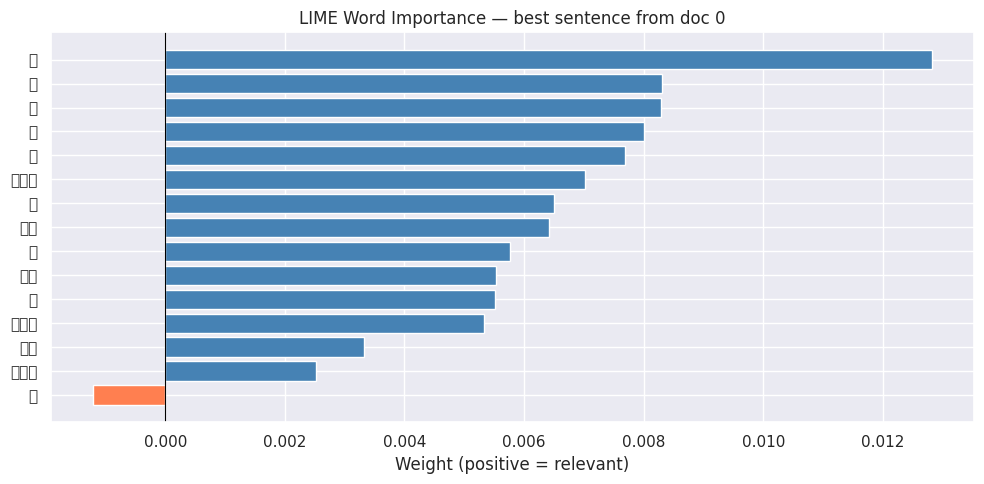

In [21]:
DOC_IDX   = 0
example   = subdf[CONFIG['text_column']].iloc[DOC_IDX]
sents     = sentence_split(example)
full_text = ' '.join(sents)

t_scores  = tfidf_scores(sents, full_text)
best_sent = sents[int(np.argmax(t_scores))]

explainer = LimeTextExplainer(class_names=['irrelevant', 'relevant'])
predictor = build_lime_predictor(sents)

exp = explainer.explain_instance(
    best_sent, predictor,
    num_features=15,
    num_samples=100,
    labels=(1,),
)

feat_list = sorted(exp.as_list(label=1), key=lambda x: x[1])
words     = [f[0] for f in feat_list]
weights   = [f[1] for f in feat_list]
colors    = ['coral' if w < 0 else 'steelblue' for w in weights]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(words, weights, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'LIME Word Importance — best sentence from doc {DOC_IDX}')
ax.set_xlabel('Weight (positive = relevant)')
plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'lime_explanation.png', dpi=150, bbox_inches='tight')
plt.show()